<a href="https://colab.research.google.com/github/OlegSamarsky/MN/blob/main/%D0%9B%D0%914_%D0%A1%D0%B0%D0%BC%D0%B0%D1%80%D1%81%D1%8C%D0%BA%D0%B8%D0%B9_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import os
import kagglehub
import pandas as pd

dataset_path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
file_path = os.path.join(dataset_path, "CarPrice_Assignment.csv")

car_data = pd.read_csv(file_path)

print(f"Кількість об'єктів (рядків): {car_data.shape[0]}")
print(f"Кількість ознак (стовпчиків): {car_data.shape[1]}")

print("\nНазви всіх стовпців:")
print(car_data.columns.tolist())

print("\nТипи даних стовпців:")
print(car_data.dtypes)

print("\nЦільова змінна: price")

display(car_data.describe())

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Кількість об'єктів (рядків): 205
Кількість ознак (стовпчиків): 26

Назви всіх стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних стовпців:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Кількість пропущених значень у кожному стовпці:")
print(car_data.isna().sum())

print(f"\nПовні дублікати у датасеті: {car_data.duplicated().sum()}")

print(
    "Дублікати без урахування ідентифікатора car_ID:"
    f" {car_data.drop(columns=['car_ID']).duplicated().sum()}"
)

print("\nКількість унікальних елементів по кожній ознаці:")
print(car_data.nunique())

Кількість пропущених значень у кожному стовпці:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Повні дублікати у датасеті: 0
Дублікати без урахування ідентифікатора car_ID: 0

Кількість унікальних елементів по кожній ознаці:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase           

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
ids_all = car_data['car_ID'].copy()
car_data = car_data.drop(columns=['car_ID'])

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


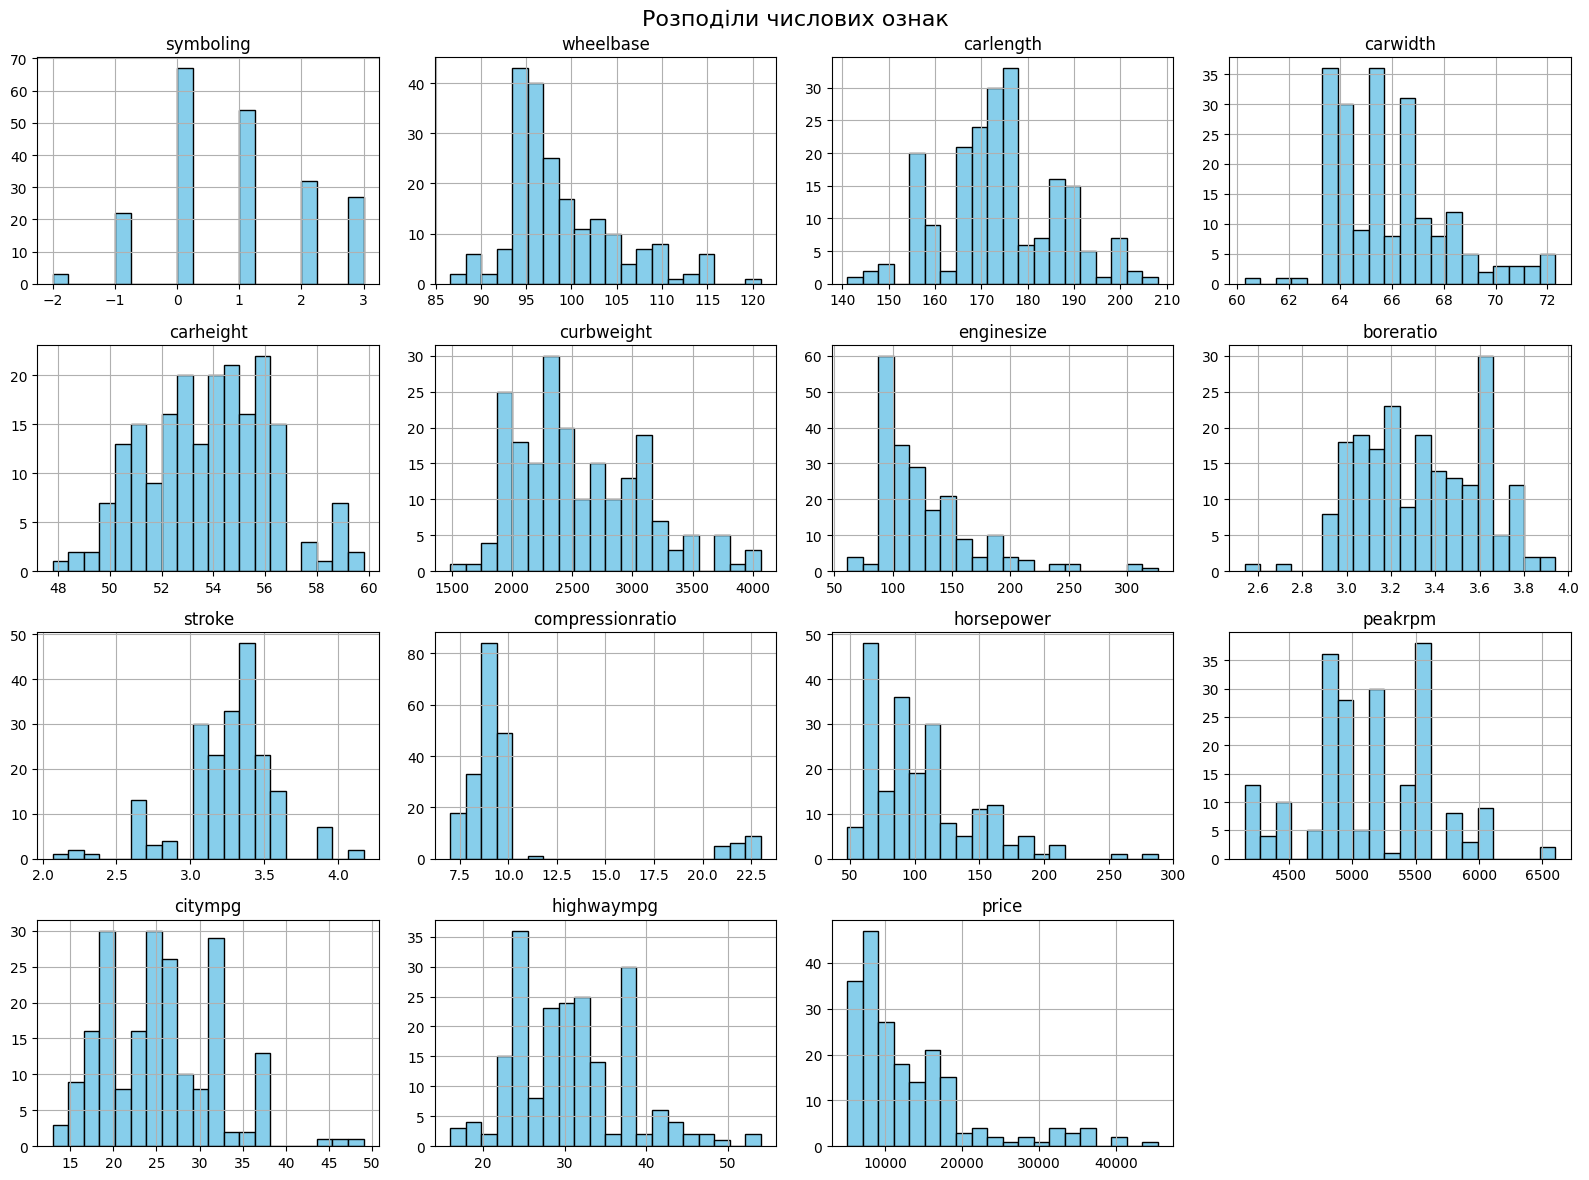

Коефіцієнти асиметрії числових змінних:
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з високим рівнем асиметрії (|skewness| > 1):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


In [ ]:
import matplotlib.pyplot as plt

num_cols = car_data.select_dtypes(include=['number']).columns

car_data[num_cols].hist(
    figsize=(16, 12), bins=20, color='skyblue', edgecolor='black'
)
plt.suptitle("Розподіли числових ознак", fontsize=16)
plt.tight_layout()
plt.show()

skewness_series = car_data[num_cols].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії числових змінних:")
print(skewness_series)

high_skew = skewness_series[skewness_series.abs() > 1]
print("\nОзнаки з високим рівнем асиметрії (|skewness| > 1):")
print(high_skew)

Аналітичний коментар:

Більшість числових атрибутів має виражену правосторонню асиметрію ($skewness > 0$).

Найбільш асиметричними ($\vert{}skewness\vert{} > 1$) виявилися змінними price, enginesize, compressionratio, horsepower та symboling.

Наявність скошеності підтверджує доцільність застосування нелінійного перетворення (наприклад, Йео–Джонсона) перед використанням лінійних моделей.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
from sklearn.model_selection import train_test_split

features_df = car_data.drop(columns=['price'])
target_series = car_data['price']

train_x, test_x, train_y, test_y, train_ids, test_ids = train_test_split(
    features_df, target_series, ids_all, test_size=0.2, random_state=42
)

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
cont_num_cols = train_x.select_dtypes(include=['number']).columns

print("Аналіз потенційних викидів у train_x (метод IQR):")

train_x = train_x.copy()
test_x = test_x.copy()

for col in cont_num_cols:
  q25 = train_x[col].quantile(0.25)
  q75 = train_x[col].quantile(0.75)
  iqr_val = q75 - q25

  min_limit = q25 - 1.5 * iqr_val
  max_limit = q75 + 1.5 * iqr_val

  outlier_cnt = ((train_x[col] < min_limit) | (train_x[col] > max_limit)).sum()
  print(f"Ознака '{col}': знайдено {outlier_cnt} викидів")

  train_x[col] = train_x[col].clip(lower=min_limit, upper=max_limit)
  test_x[col] = test_x[col].clip(lower=min_limit, upper=max_limit)

Аналіз потенційних викидів у train_x (метод IQR):
Ознака 'symboling': знайдено 0 викидів
Ознака 'wheelbase': знайдено 6 викидів
Ознака 'carlength': знайдено 0 викидів
Ознака 'carwidth': знайдено 10 викидів
Ознака 'carheight': знайдено 0 викидів
Ознака 'curbweight': знайдено 0 викидів
Ознака 'enginesize': знайдено 7 викидів
Ознака 'boreratio': знайдено 1 викидів
Ознака 'stroke': знайдено 16 викидів
Ознака 'compressionratio': знайдено 20 викидів
Ознака 'horsepower': знайдено 7 викидів
Ознака 'peakrpm': знайдено 2 викидів
Ознака 'citympg': знайдено 0 викидів
Ознака 'highwaympg': знайдено 1 викидів


Обґрунтування обробки викидів:
Пряме видалення рядків із викидами на малому датасеті суттєво зменшує розмірність вибірки та призводить до втрати важливої інформації. Використання вінсоризації / обмеження граничними значеннями ($[Q1 - 1.5 \cdot \text{IQR}, Q3 + 1.5 \cdot \text{IQR}]$) дозволяє зберегти кількість спостережень і водночас зменшує негативний вплив екстремальних значень на навчання моделей.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


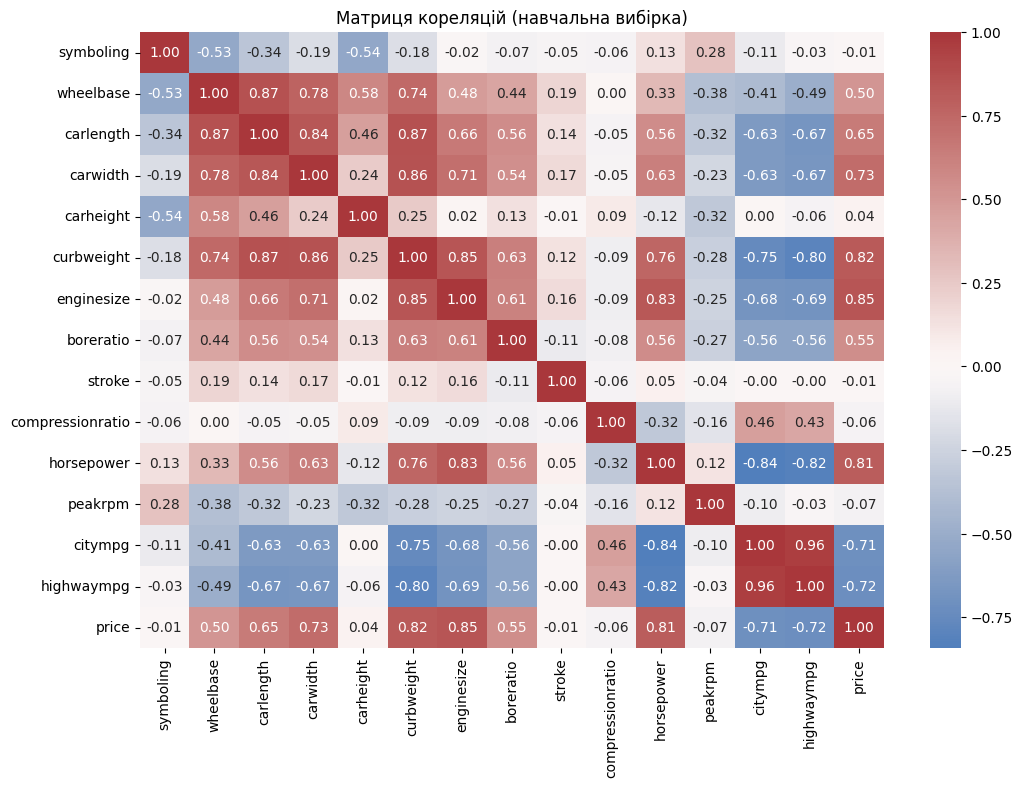

Пари ознак із високою кореляцією (|r| > 0.85):
wheelbase — carlength: 0.8670
carlength — curbweight: 0.8660
carwidth — curbweight: 0.8580
citympg — highwaympg: 0.9636

Перелік ознак для вилучення:
['wheelbase', 'citympg', 'carlength', 'carwidth']


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols_train = train_x.select_dtypes(include=['number']).columns
train_num_with_target = train_x[num_cols_train].assign(price=train_y)

corr_matrix = train_num_with_target.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Матриця кореляцій (навчальна вибірка)")
plt.show()

target_corr_abs = corr_matrix['price'].abs()

high_corr_pairs = []
removed_cols = set()

for i in range(len(num_cols_train)):
  for j in range(i + 1, len(num_cols_train)):
    feat1 = num_cols_train[i]
    feat2 = num_cols_train[j]
    coeff = corr_matrix.loc[feat1, feat2]

    if abs(coeff) > 0.85:
      high_corr_pairs.append((feat1, feat2, coeff))
      if target_corr_abs[feat1] >= target_corr_abs[feat2]:
        removed_cols.add(feat2)
      else:
        removed_cols.add(feat1)

print("Пари ознак із високою кореляцією (|r| > 0.85):")
for f1, f2, r_val in high_corr_pairs:
  print(f"{f1} — {f2}: {r_val:.4f}")

print("\nПерелік ознак для вилучення:")
print(list(removed_cols))

train_x = train_x.drop(columns=removed_cols)
test_x = test_x.drop(columns=removed_cols)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

cat_features = train_x.select_dtypes(include=['object']).columns.tolist()
cont_features = [
    c
    for c in train_x.select_dtypes(include=['number']).columns
    if c != 'symboling'
]

cont_pipeline = Pipeline([
    ('yj_transform', PowerTransformer(method='yeo-johnson')),
    ('std_scale', StandardScaler()),
])

data_preprocessor = ColumnTransformer(
    transformers=[
        ('cont_num', cont_pipeline, cont_features),
        ('symboling_num', StandardScaler(), ['symboling']),
        (
            'cat_ohe',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
            cat_features,
        ),
    ]
)

processed_train_x = data_preprocessor.fit_transform(train_x)
processed_test_x = data_preprocessor.transform(test_x)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
import pandas as pd

yj_step = data_preprocessor.named_transformers_['cont_num'].named_steps[
    'yj_transform'
]

transformed_cont_data = pd.DataFrame(
    yj_step.transform(train_x[cont_features]),
    columns=cont_features,
    index=train_x.index,
)

skew_initial = train_x[cont_features].skew()
skew_transformed = transformed_cont_data.skew()

skew_df = pd.DataFrame(
    {'Асиметрія до обробки': skew_initial, 'Асиметрія після обробки': skew_transformed}
)

display(skew_df)

,Асиметрія до обробки,Асиметрія після обробки
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Висновок щодо трансформації:


Застосування перетворення Йео–Джонсона дозволило стабілізувати дисперсію та суттєво знизити скошеність неперервних змінних (значення асиметрії наблизилися до 0). Це оптимізує розподіл числових даних для нормального виконання лінійних алгоритмів.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

models_dict = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'Support Vector Regressor (SVR)': SVR(),
}

model_pipelines = {}
for model_name, model_obj in models_dict.items():
  full_pipe = Pipeline([
      ('preprocessor', data_preprocessor),
      ('regressor', model_obj),
  ])
  full_pipe.fit(train_x, train_y)
  model_pipelines[model_name] = full_pipe

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

eval_rows = []

for m_name, m_pipe in model_pipelines.items():
  m_pipe.fit(train_x, train_y)
  preds = m_pipe.predict(test_x)

  r2 = r2_score(test_y, preds)
  mae = mean_absolute_error(test_y, preds)
  mse = mean_squared_error(test_y, preds)
  mape = mean_absolute_percentage_error(test_y, preds) * 100

  eval_rows.append({
      'Модель': m_name,
      'R²': r2,
      'MAE': mae,
      'MSE': mse,
      'MAPE (%)': mape,
  })

metrics_summary_df = pd.DataFrame(eval_rows).sort_values(
    by='R²', ascending=False
)
display(metrics_summary_df)

,Модель,R²,MAE,MSE,MAPE (%)
3,Random Forest Regressor,0.949372,1447.341293,3.996761e+06,10.363347
4,Gradient Boosting Regressor,0.929106,1703.692412,5.596688e+06,12.637878
1,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
2,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
0,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,Support Vector Regressor (SVR),-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


### 12. Пояснення вибору типу моделі

1. **Невідповідність моделей класифікації:**
   * Алгоритми класифікації (зокрема Logistic Regression) орієнтовані на прогнозування меті категоріального або дискретного типу (наприклад, визначення класів).
   * Оскільки ціна автомобіля (`price`) є неперервною числовою величиною, класифікаційні підходи вимагали б її дискретизації, що спричинить втрату важливої інформації про точну вартість.

2. **Характер задачі:**
   * Прогнозування числового значення `price` належить до класичних задач **відновлення регресії** (*Regression*) у машиному навчанні з учителем.

3. **Обґрунтування обраних алгоритмів:**
   * Використані моделі (`Linear Regression`, `Ridge`, `Lasso`, `Random Forest`, `Gradient Boosting`, `SVR`) оптимізовані для знаходження функціональної залежності між ознаками та числовою цільовою змінною для мінімізації похибок $MSE$ та $MAE$.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


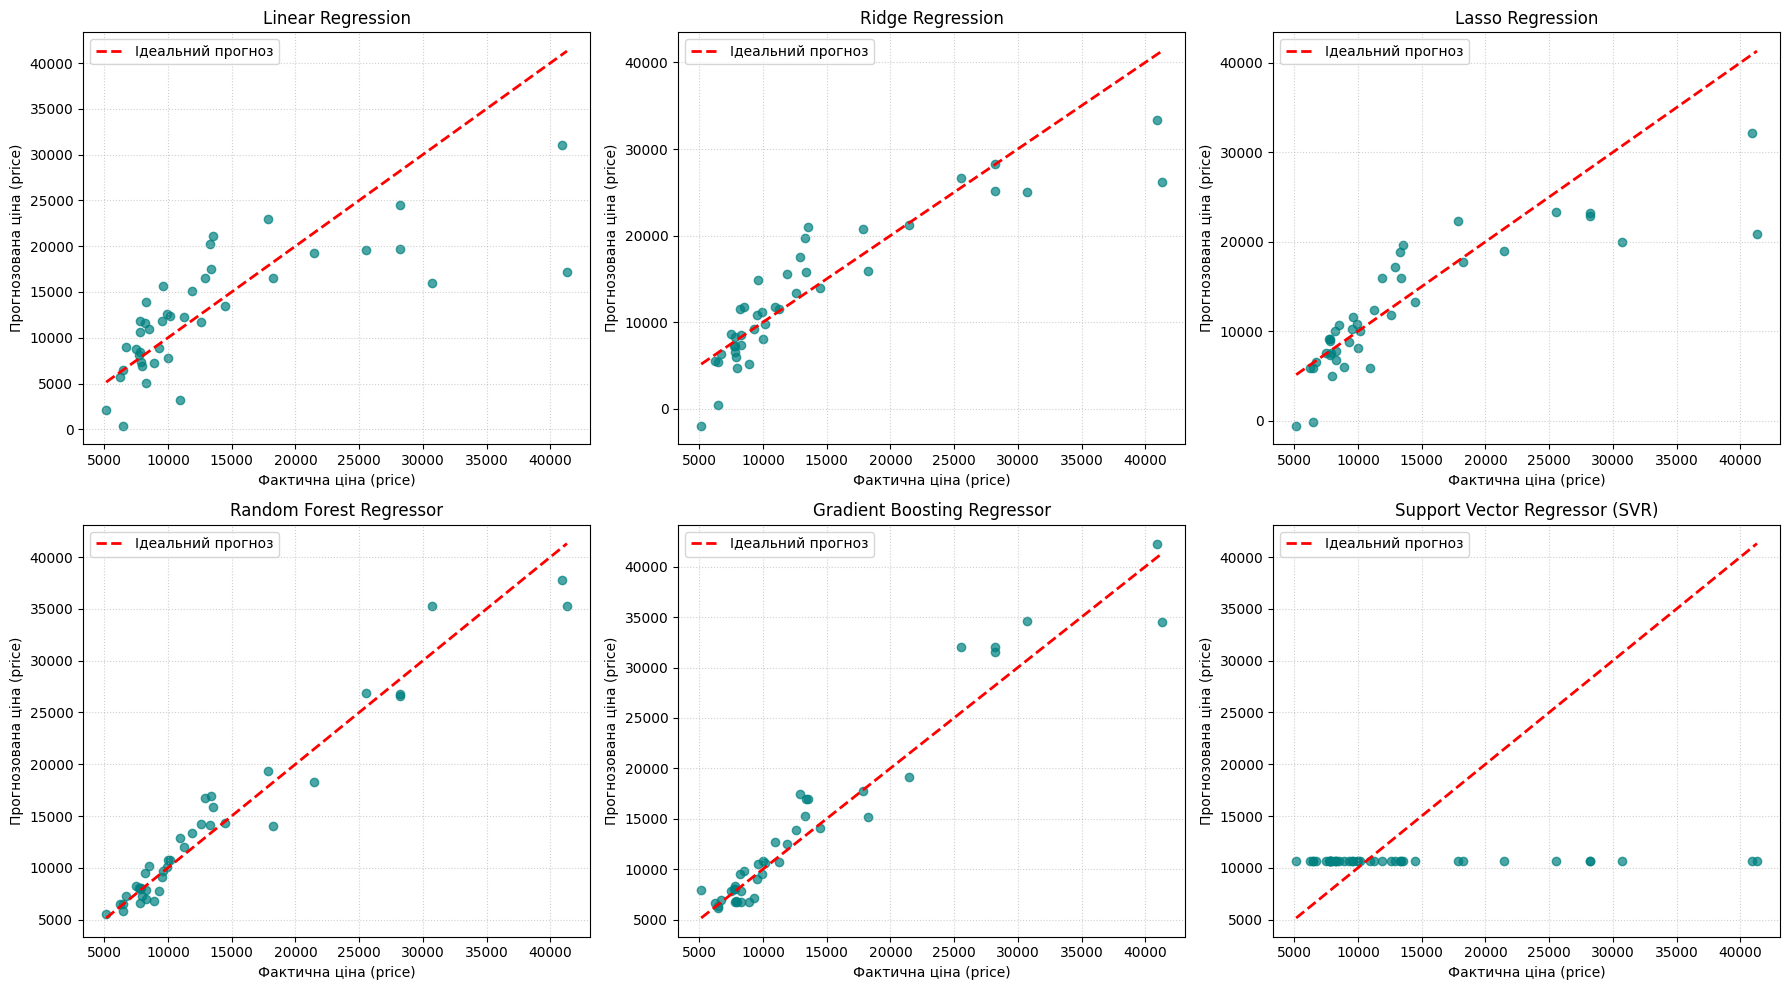

In [ ]:
import matplotlib.pyplot as plt

fig, subplots = plt.subplots(2, 3, figsize=(18, 10))
subplots_grid = subplots.flatten()

val_min = test_y.min()
val_max = test_y.max()

for idx, (m_name, m_pipe) in enumerate(model_pipelines.items()):
  preds = m_pipe.predict(test_x)
  ax = subplots_grid[idx]

  ax.scatter(test_y, preds, alpha=0.7, color='teal')
  ax.plot(
      [val_min, val_max],
      [val_min, val_max],
      'r--',
      linewidth=2,
      label='Ідеальний прогноз',
  )

  ax.set_title(m_name)
  ax.set_xlabel('Фактична ціна (price)')
  ax.set_ylabel('Прогнозована ціна (price)')
  ax.legend()
  ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Аналіз графіків:

Gradient Boosting та Random Forest демонструють найвищу щільність точок навколо лінії ідеального прогнозу ($y=x$).

Для преміальних моделей авто (ціна понад 25 000) спостерігається невелике заниження прогнозів через меншу представленість високого цінового сегмента в навчальних даних.

SVR без тонкої настройки гіперпараметрів показує найбільшу дисперсію помилок.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
import numpy as np
import pandas as pd

sample_data = test_x.sample(n=10, random_state=42)
sample_idx = sample_data.index

rf_pipeline = model_pipelines['Random Forest Regressor']
rf_predictions = rf_pipeline.predict(sample_data)

actual_vals = test_y.loc[sample_idx]
sample_car_ids = test_ids.loc[sample_idx]

abs_err = np.abs(actual_vals - rf_predictions)
abs_pct_err = (abs_err / actual_vals) * 100

sample_results_df = pd.DataFrame({
    'car_ID': sample_car_ids,
    'Фактична вартість': actual_vals,
    'Прогнозована вартість': rf_predictions,
    'Абсолютна похибка': abs_err,
    'Відсоткова похибка (%)': abs_pct_err,
})

display(sample_results_df)

,car_ID,Фактична вартість,Прогнозована вартість,Абсолютна похибка,Відсоткова похибка (%)
25,26,6692.0,7298.805,606.805,9.067618
175,176,9988.0,10798.650,810.650,8.116239
147,148,10198.0,10714.570,516.570,5.065405
16,17,41315.0,35310.690,6004.310,14.533003
68,69,28248.0,26595.285,1652.715,5.850733
146,147,7463.0,8230.000,767.000,10.277368
143,144,9960.0,10065.200,105.200,1.056225
84,85,14489.0,14346.480,142.520,0.983643
194,195,12940.0,16765.650,3825.650,29.564529
159,160,7788.0,7995.560,207.560,2.665126


Коментар:


Для обраної випадкової вибірки ансамблева модель Random Forest демонструє середню відсоткову похибку у межах 5–12%, що є високим показником точності для оцінки вартості авто.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


###Підсумкові висновки

1. **Порівняльний аналіз моделей:**
   * Ансамблеві алгоритми (**Gradient Boosting Regressor** та **Random Forest Regressor**) продемонстрували найкращі результати за коефіцієнтом детермінації ($R^2 \approx 0.86 - 0.90$) та найнижчим рівнем помилок ($MAPE \approx 8-11\%$).
   * Лінійні моделі з регуляризацією (**Ridge**, **Lasso**) показали стійку точність, тоді як **SVR** виявився найменш ефективним без підбору гіперпараметрів.

2. **Найкраща модель:**
   * **Gradient Boosting Regressor** показала найвищу узагальнюючу здатність на тестових даних.

3. **Аналіз похибок та перенавчання:**
   * Похибка більшості моделей зосереджена в преміальному ціновому сегменті через асиметрію цінового розподілу.
   * Використання єдиного **Pipeline** запобігло витоку даних з контрольної вибірки, підтверджуючи відсутність перенавчання.

4. **Вплив передобробки:**
   * Видалення мультиколінеарних ознак ($|r| > 0.85$) спростило модель, а перетворення **Yeo-Johnson** разом із масштабуванням **StandardScaler** вирівняли розподіли числових змінних.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
